# House Prices: Advanced Regression Techniques

**Dataset:** Kaggle competition data with 1,460 houses sold in Ames, Iowa (2006–2010), described by 79 features (size, quality, age, garage, basement, neighborhood, etc.) plus `Id`.

**Goal:** Predict `SalePrice` for each house. Kaggle scores submissions by RMSE on log(SalePrice).

## notes

.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import pandas as pd

In [3]:
df = pd.read_csv('/content/drive/MyDrive/data_dir/House Prices - Advanced Regression Techniques/house_prices/house_prices_project/train.csv')

In [4]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [5]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


## EDA plots

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew

plt.rcParams['figure.dpi'] = 110

### Target distribution: raw vs log1p

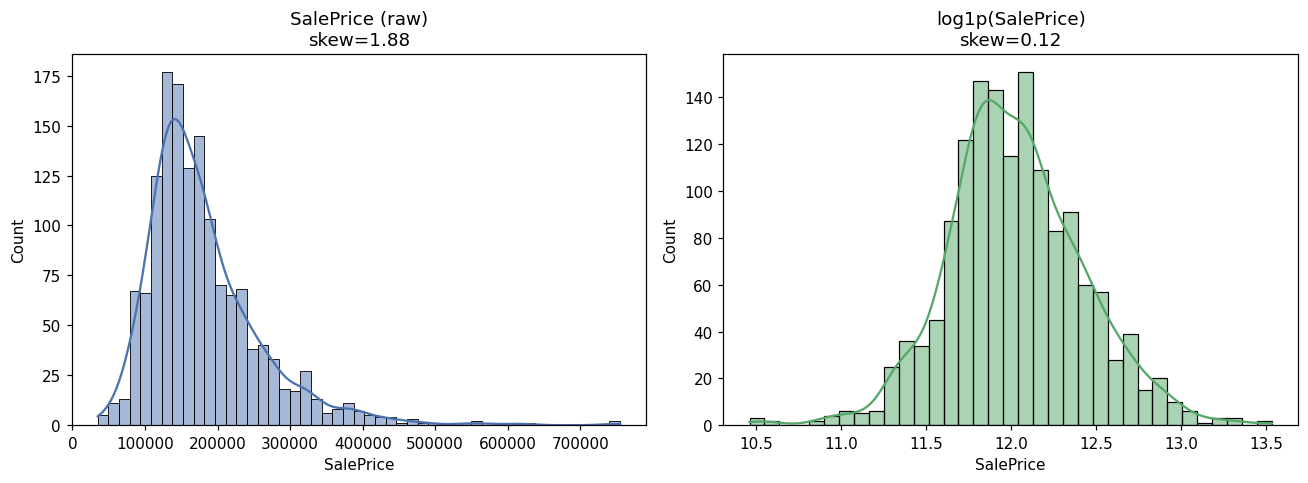

In [7]:
def plot_target_distribution(df, target='SalePrice'):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    sns.histplot(df[target], kde=True, ax=axes[0], color='#4C72B0')
    axes[0].set_title(f"{target} (raw)\nskew={df[target].skew():.2f}")
    sns.histplot(np.log1p(df[target]), kde=True, ax=axes[1], color='#55A868')
    axes[1].set_title(f"log1p({target})\nskew={np.log1p(df[target]).skew():.2f}")
    plt.tight_layout()
    plt.show()


plot_target_distribution(df)

### Missing values by feature

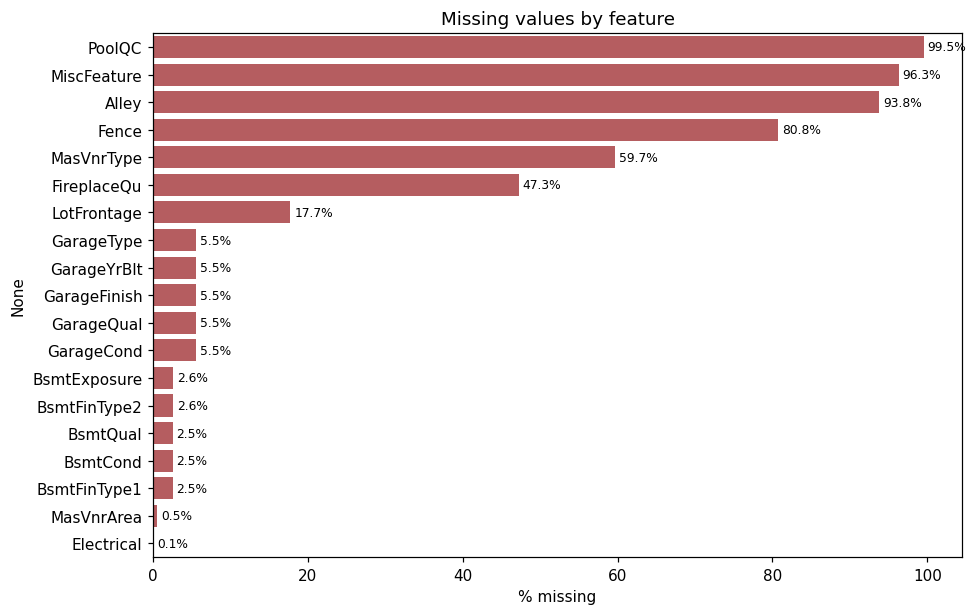

,0
PoolQC,99.520548
MiscFeature,96.301370
Alley,93.767123
Fence,80.753425
MasVnrType,59.726027
FireplaceQu,47.260274
LotFrontage,17.739726
GarageType,5.547945
GarageYrBlt,5.547945
GarageFinish,5.547945


In [8]:
def plot_missingness(df):
    miss = df.isnull().sum()
    miss = miss[miss > 0].sort_values(ascending=False)
    miss_pct = miss / len(df) * 100
    fig, ax = plt.subplots(figsize=(9, max(4, len(miss_pct) * 0.3)))
    sns.barplot(x=miss_pct.values, y=miss_pct.index, ax=ax, color='#C44E52')
    ax.set_xlabel('% missing')
    ax.set_title('Missing values by feature')
    for i, v in enumerate(miss_pct.values):
        ax.text(v + 0.5, i, f'{v:.1f}%', va='center', fontsize=8)
    plt.tight_layout()
    plt.show()
    return miss_pct


plot_missingness(df)

### Correlation heatmap

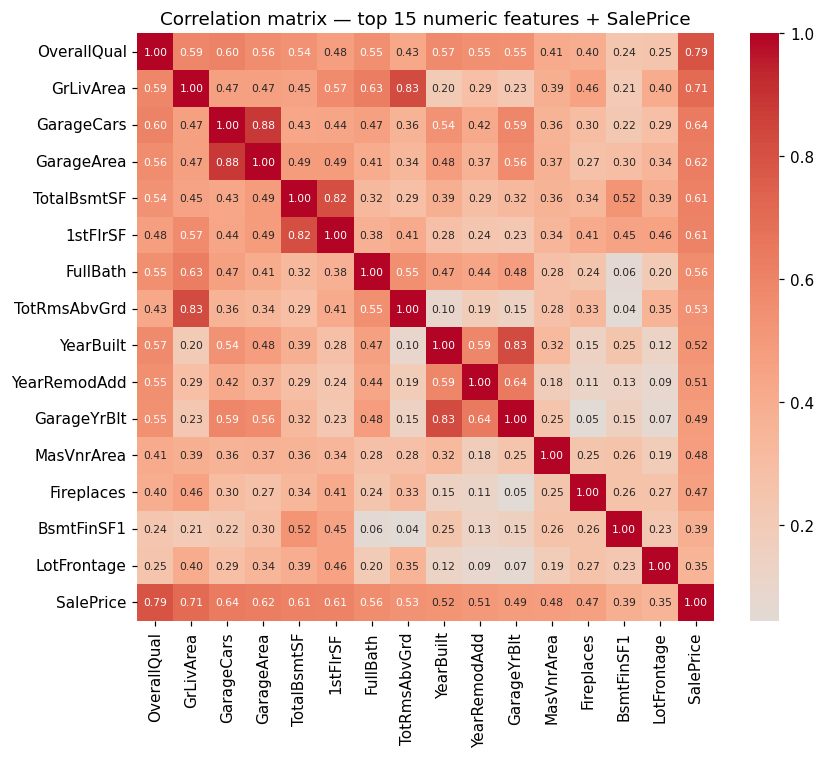

In [9]:
def plot_correlation_heatmap(df, target='SalePrice', top_n=15):
    numeric = df.select_dtypes(include=['int64', 'float64'])
    corr = numeric.corr()[target].drop(target).sort_values(ascending=False)
    top_features = corr.abs().sort_values(ascending=False).head(top_n).index.tolist()

    fig, ax = plt.subplots(figsize=(8, 7))
    sns.heatmap(numeric[top_features + [target]].corr(), annot=True, fmt='.2f',
                cmap='coolwarm', center=0, ax=ax, annot_kws={'size': 7})
    ax.set_title(f'Correlation matrix — top {top_n} numeric features + {target}')
    plt.tight_layout()
    plt.show()
    return corr


corr = plot_correlation_heatmap(df)

### Top features vs SalePrice (outliers in red)

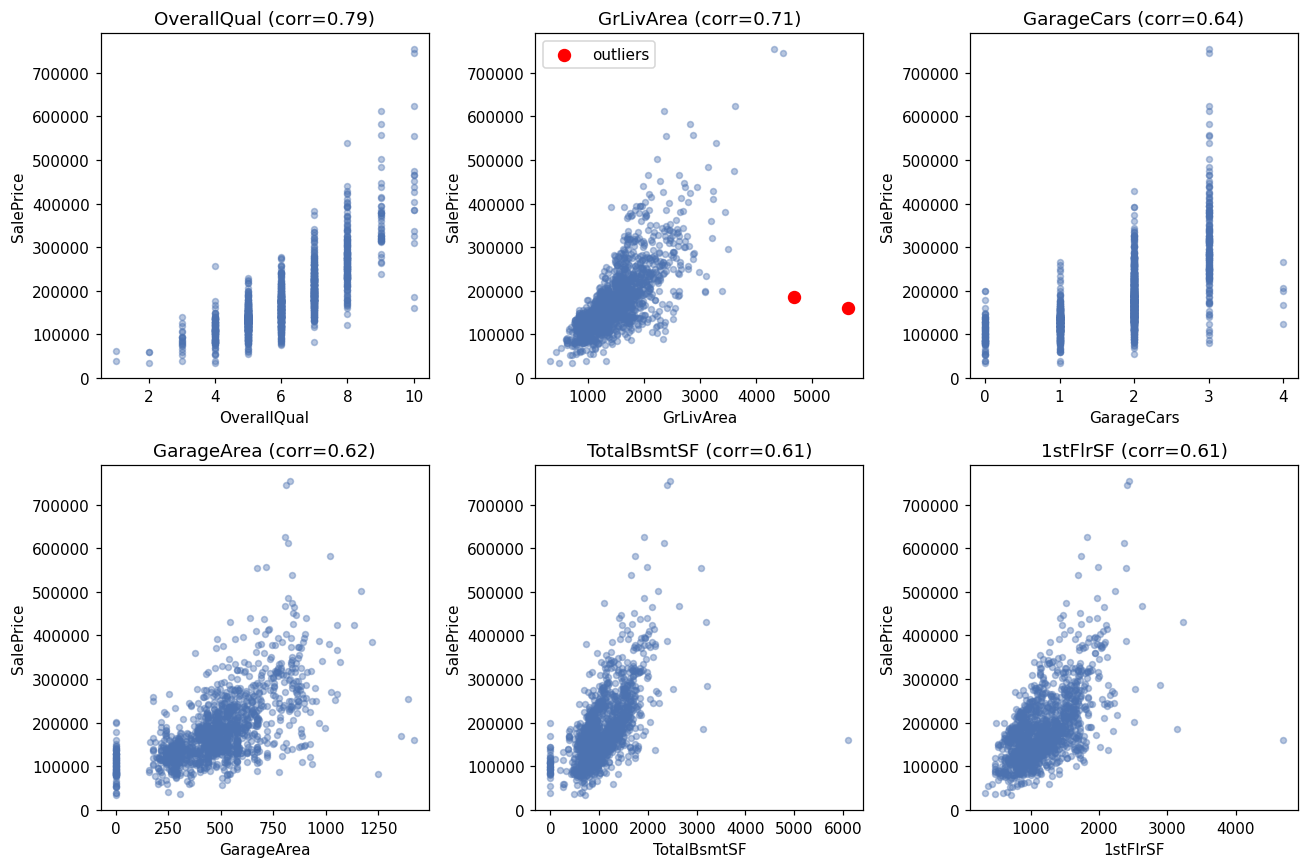

In [10]:
def plot_top_scatter(df, corr, target='SalePrice', n=6, outlier_query=None):
    """
    outlier_query: optional tuple (feature, condition_fn) to highlight points, e.g.
        outlier_query=('GrLivArea', lambda d: (d['GrLivArea']>4000) & (d[target]<300000))
    """
    top_feats = corr.abs().sort_values(ascending=False).head(n).index.tolist()
    fig, axes = plt.subplots(2, (n + 1) // 2, figsize=(4 * ((n + 1) // 2), 8))
    for ax, feat in zip(axes.flat, top_feats):
        ax.scatter(df[feat], df[target], alpha=0.4, s=15, color='#4C72B0')
        ax.set_xlabel(feat)
        ax.set_ylabel(target)
        ax.set_title(f'{feat} (corr={corr[feat]:.2f})')
    if outlier_query is not None:
        feat, cond = outlier_query
        outliers = df[cond(df)]
        for ax, f in zip(axes.flat, top_feats):
            if f == feat and len(outliers):
                ax.scatter(outliers[feat], outliers[target], color='red', s=60, label='outliers')
                ax.legend()
    plt.tight_layout()
    plt.show()


plot_top_scatter(
    df, corr, n=6,
    outlier_query=('GrLivArea', lambda d: (d['GrLivArea'] > 4000) & (d['SalePrice'] < 300000))
)

### Categorical features vs SalePrice

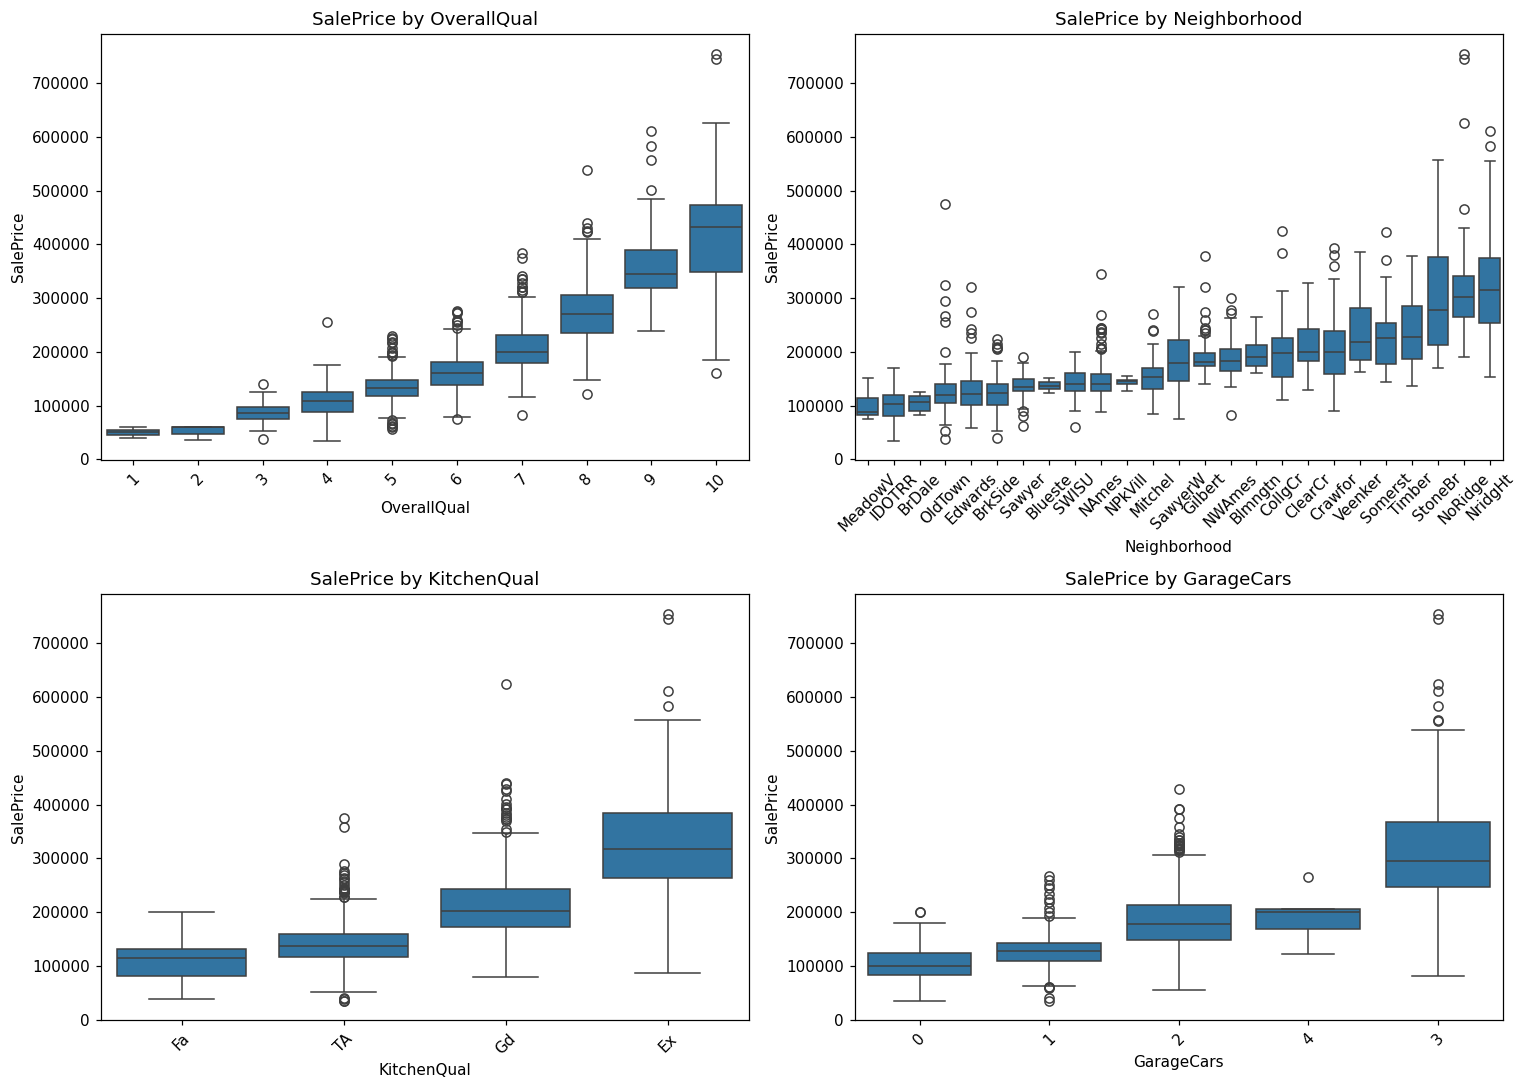

In [11]:
def plot_categorical_boxplots(df, features, target='SalePrice'):
    n = len(features)
    ncols = 2
    nrows = (n + 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(7 * ncols, 5 * nrows))
    axes = axes.flat if n > 1 else [axes]
    for ax, feat in zip(axes, features):
        order = df.groupby(feat)[target].median().sort_values().index
        sns.boxplot(data=df, x=feat, y=target, order=order, ax=ax)
        ax.set_title(f'{target} by {feat}')
        ax.tick_params(axis='x', rotation=45)
    plt.tight_layout()
    plt.show()


plot_categorical_boxplots(df, ['OverallQual', 'Neighborhood', 'KitchenQual', 'GarageCars'])

### Skewness of numeric features

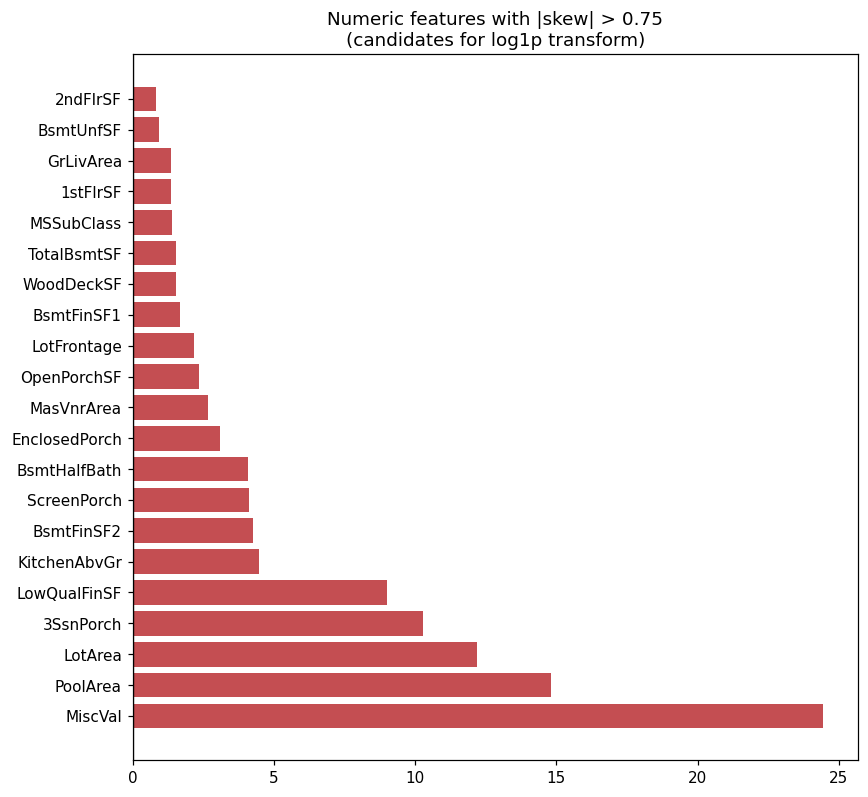

,0
MiscVal,24.451640
PoolArea,14.813135
LotArea,12.195142
3SsnPorch,10.293752
LowQualFinSF,9.002080
KitchenAbvGr,4.483784
BsmtFinSF2,4.250888
ScreenPorch,4.117977
BsmtHalfBath,4.099186
EnclosedPorch,3.086696


In [12]:
def plot_skewness(df, target='SalePrice', threshold=0.75):
    numeric = df.select_dtypes(include=['int64', 'float64']).drop(columns=['Id', target], errors='ignore')
    skews = numeric.apply(lambda x: skew(x.dropna())).sort_values(ascending=False)
    skews_top = skews[abs(skews) > threshold]
    fig, ax = plt.subplots(figsize=(8, max(4, len(skews_top) * 0.35)))
    colors = ['#C44E52' if v > 0 else '#4C72B0' for v in skews_top.values]
    ax.barh(skews_top.index, skews_top.values, color=colors)
    ax.axvline(0, color='black', lw=0.8)
    ax.set_title(f'Numeric features with |skew| > {threshold}\n(candidates for log1p transform)')
    plt.tight_layout()
    plt.show()
    return skews_top


plot_skewness(df)

## Handling the missing values

In [13]:
miss_values = df.isnull().sum()[df.isnull().sum() > 0]
print(miss_values.sort_values(ascending=False))

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64


In [14]:
# missing values
print(f'{miss_values.sum()} missing values')

# categorical features
cat_features = df.select_dtypes(include=['object']).shape[1]
print(f"{cat_features} categorical features")

# numerical features
num_features = df.select_dtypes(include=['int64', 'float64']).shape[1]
print(f"{num_features} numerical features")

# shape
print(f"\n{df.shape[0]} enteries, {df.shape[1]} features")

7829 missing values
43 categorical features
38 numerical features

1460 enteries, 81 features


## Reports
We have 1460 enteries and 81 features
7829 missing values  
43 categorical features  
38 numerical features  

## Training a "baseline" linear model, (( without the missing values ))

In [15]:
# Select only numerical columns
df_numeric = df.select_dtypes(include=['int64', 'float64'])

# Drop rows with any missing values
df_cl_baseline = df_numeric.dropna(axis=0)

print(f"Original shape: {df.shape}")
print(f"Numeric shape: {df_numeric.shape}")
print(f"Clean shape: {df_cl_baseline.shape}")

Original shape: (1460, 81)
Numeric shape: (1460, 38)
Clean shape: (1121, 38)


## Spliting the data, training and baseline resualts

In [16]:
from sklearn.model_selection import train_test_split, cross_val_score

In [17]:
X = df_cl_baseline.drop(['SalePrice', 'Id'], axis=1)
y = df_cl_baseline['SalePrice']

# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [18]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
cv_scores = cross_val_score(
    model,
    X,
    y,
    scoring="neg_root_mean_squared_error",
    cv=5
)
rmse_scores = -cv_scores

print("RMSE scores:", rmse_scores)
print("Mean RMSE:", rmse_scores.mean())
print("Std RMSE:", rmse_scores.std())


RMSE scores: [29587.07709133 37665.99103449 40100.65600937 32378.41339688
 54086.83339133]
Mean RMSE: 38763.794184682316
Std RMSE: 8517.900283988249


# Above is the result for our baseline model.

#Removing outliers

In [19]:
#huge houses that sold cheap
big_cheap = (df['GrLivArea'] > 4000) & (df['SalePrice'] < 300000)

#huge garages that sold cheap
big_garage = (df['GarageArea'] > 1200) & (df['SalePrice'] < 300000)

outliers = big_cheap | big_garage

#check before removing
print(df.loc[outliers, ['Id', 'GrLivArea', 'TotalBsmtSF', '1stFlrSF', 'GarageArea', 'SalePrice']])

df = df[~outliers].reset_index(drop=True)
print(df.shape)

        Id  GrLivArea  TotalBsmtSF  1stFlrSF  GarageArea  SalePrice
523    524       4676         3138      3138         884     184750
581    582       2042         2042      2042        1390     253293
1061  1062        894          894       894        1248      81000
1190  1191       1622         1249      1622        1356     168000
1298  1299       5642         6110      4692        1418     160000
(1455, 81)


#Top features vs SalePrice (without outliers)

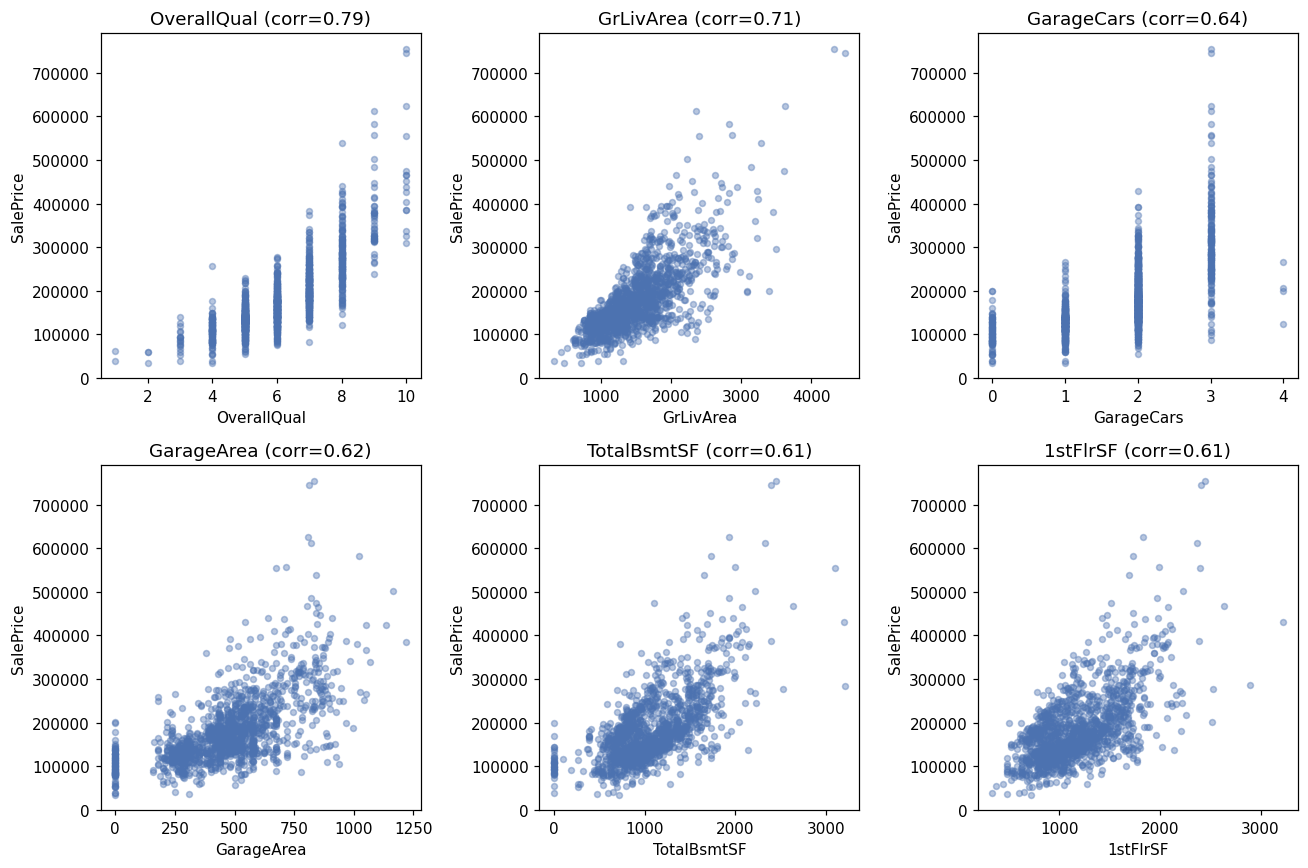

In [20]:
def plot_top_scatter(df, corr, target='SalePrice', n=6, outlier_query=None):
    """
    outlier_query: optional tuple (feature, condition_fn) to highlight points, e.g.
        outlier_query=('GrLivArea', lambda d: (d['GrLivArea']>4000) & (d[target]<300000))
    """
    top_feats = corr.abs().sort_values(ascending=False).head(n).index.tolist()
    fig, axes = plt.subplots(2, (n + 1) // 2, figsize=(4 * ((n + 1) // 2), 8))
    for ax, feat in zip(axes.flat, top_feats):
        ax.scatter(df[feat], df[target], alpha=0.4, s=15, color='#4C72B0')
        ax.set_xlabel(feat)
        ax.set_ylabel(target)
        ax.set_title(f'{feat} (corr={corr[feat]:.2f})')
    if outlier_query is not None:
        feat, cond = outlier_query
        outliers = df[cond(df)]
        for ax, f in zip(axes.flat, top_feats):
            if f == feat and len(outliers):
                ax.scatter(outliers[feat], outliers[target], color='red', s=60, label='outliers')
                ax.legend()
    plt.tight_layout()
    plt.show()


plot_top_scatter(
    df, corr, n=6,
    outlier_query=('GrLivArea', lambda d: (d['GrLivArea'] > 4000) & (d['SalePrice'] < 300000))
)

# Pipelines, Imputers, preprocessing and model

In [21]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import Ridge

In [22]:
X = df.drop(['SalePrice', 'Id'], axis=1)
y = df['SalePrice']

num_features = X.select_dtypes(include=['int64', 'float64']).columns

# for some features missing value has meaning, like Garage year build (house has no garage), can't be replaced with median or mode.
# same with masanory area. so its best to fill with zero.
num_zero_features = ['GarageYrBlt', 'MasVnrArea']
# sounds odd to say 0 for garage year built, but after cross-validation, decided to keep as 0.

# avoiding overlaping
num_features = num_features.drop(['GarageYrBlt', 'MasVnrArea'])


cat_cols = X.select_dtypes(exclude='number').columns          # all text columns

cat_mode_features = ['Electrical']                             # a real gap: use the most common value
cat_none_features = [c for c in cat_cols
                     if X[c].isnull().any() and c not in cat_mode_features]   # missing = "doesn't have it"
cat_other_features = [c for c in cat_cols
                      if c not in cat_none_features + cat_mode_features]       # no missing values


In [23]:
num_median_transformer = Pipeline([(
    "imputer", SimpleImputer(strategy='median'))
])
num_zero_transformer = Pipeline([(
    "imputer", SimpleImputer(strategy='constant', fill_value=0))
])

cat_none_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="None")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
cat_mode_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])


preprocessor = ColumnTransformer(
    transformers=[
        ("num_median", num_median_transformer, num_features),
        ("num_zero", num_zero_transformer, num_zero_features),
        ("cat_none", cat_none_transformer, cat_none_features),
        ("cat_mode", cat_mode_transformer, cat_mode_features),
        ("cat_other", OneHotEncoder(handle_unknown='ignore'), cat_other_features)
    ]
)


In [24]:
print(set(X.columns) - set(num_features) - set(num_zero_features)
      - set(cat_none_features) - set(cat_mode_features) - set(cat_other_features))   # set() = nothing forgotten

set()


# Finding the best alpha for ridge


#NOTE:IS THERE NO OTHER METHOD TO FIND BEST ALPHA?

manually
alpha=0.01   mean RMSE=36144 | std=8429  
alpha=0.1    mean RMSE=35334 | std=7744  
alpha=1.0    mean RMSE=34664 | std=7529  
alpha=10     mean RMSE=34151 | std=7583  
alpha=100    mean RMSE=34223 | std=7760  

**alpha = 10**
- Mean RMSE is clearly lower
- Std barely increases (still very stable)
- No sign of underfitting yet

# Running Ridge with CV and best alpha

In [25]:
ridge = Pipeline([('preprocess', preprocessor), ('model', Ridge(alpha=10))])

In [26]:
cv_scores = cross_val_score(
    ridge,
    X,
    y,
    scoring="neg_root_mean_squared_error",
    cv=5
)
ridge_rmse_scores = -cv_scores

In [27]:
print("RMSE scores:", ridge_rmse_scores)
print("Mean RMSE:", ridge_rmse_scores.mean())
print("Std RMSE:", ridge_rmse_scores.std())

RMSE scores: [27346.16890515 23256.47571908 32498.78256699 26084.31344038
 31062.50526884]
Mean RMSE: 28049.649180087214
Std RMSE: 3352.7311434212784


# Linear regression results
RMSE scores: [29599.84709821 35696.85172911 42926.73509051 24871.91900602
 48913.65432257]  
Mean RMSE: 36401.801449283426  
Std RMSE: 8704.285698468633  

# comparision results:  
after running data through a simple pipeline. the resaults are not that different since we only filled the numerical missing values. and there are not that many numerical missing values in our data.  
the missing values are about %95 categorical.  

around ~2k less error in mean RMSE

and that is using LinearRegression.

after using a proper pipeline, with all the categorical and numerical features for Ridge model. the results are just a little bit better which is totally disapointing. but more realistic now.

#Plotting Residuals
considering log target ridge

In [28]:
from sklearn.model_selection import cross_val_predict

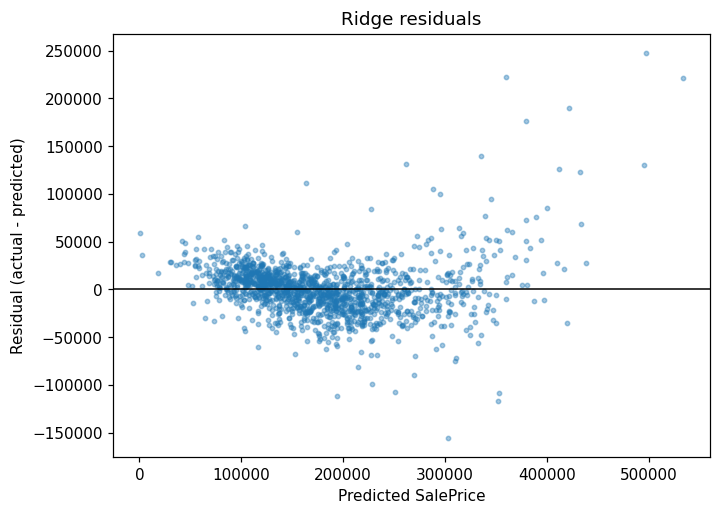

In [29]:
pred = cross_val_predict(ridge, X, y, cv=5)
resid = y - pred

plt.figure(figsize=(7, 5))
plt.scatter(pred, resid, s=8, alpha=0.4)
plt.axhline(0, color='black', lw=1)
plt.xlabel('Predicted SalePrice')
plt.ylabel('Residual (actual - predicted)')
plt.title('Ridge residuals')
plt.show()

#From residual plot
1. model error scale with price.
2. there is a curve.
3. there is a house predicted very close to $0.

#Ridge with log target
1. Remove outliers

2. Ridge log target transformed



In [30]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import mean_squared_error

In [31]:
ridge_log = TransformedTargetRegressor(
    regressor=Pipeline([('preprocess', preprocessor), ('model', Ridge(alpha=10))]),
    func=np.log1p,
    inverse_func=np.expm1
)


kf = KFold(n_splits=5)
ridge_pred = cross_val_predict(ridge_log, X, y, cv=kf)
ridge_resid = y - ridge_pred

# RMSE in dollars
rmse_dollars = np.array([np.sqrt(mean_squared_error(y.iloc[val], ridge_pred[val]))
                         for _, val in kf.split(X)])
# RMSE on the log scale
rmse_log = np.array([np.sqrt(mean_squared_error(np.log1p(y.iloc[val]), np.log1p(ridge_pred[val])))
                     for _, val in kf.split(X)])

print("RMSE ($):", rmse_dollars.round(0), "| mean:", rmse_dollars.mean().round(0))
print("RMSE (log):", rmse_log.round(4), "| mean:", rmse_log.mean().round(4))


RMSE ($): [21890. 20613. 26247. 22292. 23358.] | mean: 22880.0
RMSE (log): [0.1214 0.126  0.1352 0.1184 0.1236] | mean: 0.1249


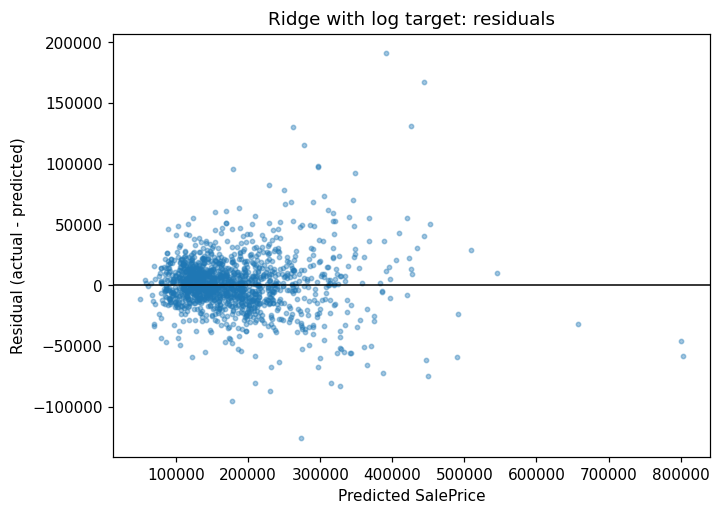

In [32]:
plt.figure(figsize=(7, 5))
plt.scatter(ridge_pred, ridge_resid, s=8, alpha=0.4)
plt.axhline(0, color='black', lw=1)
plt.xlabel('Predicted SalePrice')
plt.ylabel('Residual (actual - predicted)')
plt.title('Ridge with log target: residuals')
plt.show()

#Gradient Boosting on data without outliers and log target

In [33]:
from sklearn.ensemble import GradientBoostingRegressor

In [34]:
gb_log = TransformedTargetRegressor(
    regressor=Pipeline([('preprocess', preprocessor),
                        ('model', GradientBoostingRegressor(n_estimators=2000, learning_rate=0.01,
                                                            max_depth=3, subsample=0.8, random_state=42))]),
    func=np.log1p, inverse_func=np.expm1
)

kf = KFold(n_splits=5)
gb_pred = cross_val_predict(gb_log, X, y, cv=kf)
gb_resid = y - gb_pred

# RMSE in dollars
rmse_dollars = np.array([np.sqrt(mean_squared_error(y.iloc[val], gb_pred[val]))
                         for _, val in kf.split(X)])
# RMSE on the log scale
rmse_log = np.array([np.sqrt(mean_squared_error(np.log1p(y.iloc[val]), np.log1p(gb_pred[val])))
                     for _, val in kf.split(X)])

print("RMSE ($):", rmse_dollars.round(0), "| mean:", rmse_dollars.mean().round(0))
print("RMSE (log):", rmse_log.round(4), "| mean:", rmse_log.mean().round(4))


RMSE ($): [21265. 19988. 26309. 17747. 23977.] | mean: 21857.0
RMSE (log): [0.1081 0.1203 0.1249 0.1063 0.117 ] | mean: 0.1153


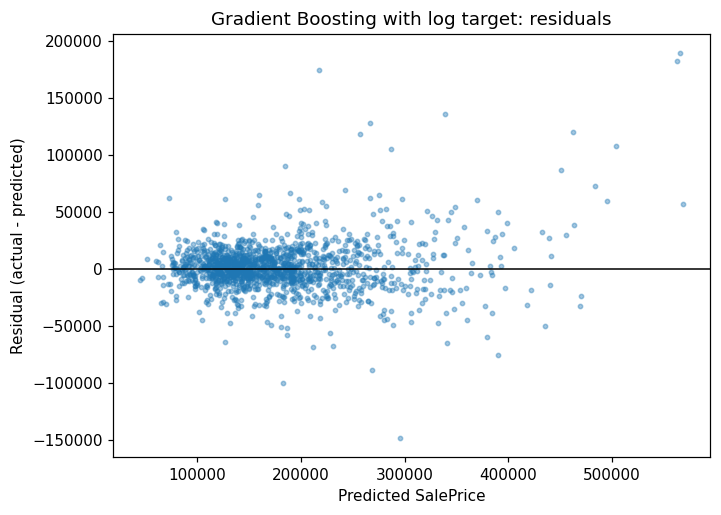

In [42]:
plt.figure(figsize=(7, 5))
plt.scatter(gb_pred, gb_resid, s=8, alpha=0.4)
plt.axhline(0, color='black', lw=1)
plt.xlabel('Predicted SalePrice')
plt.ylabel('Residual (actual - predicted)')
plt.title('Gradient Boosting with log target: residuals')
plt.show()

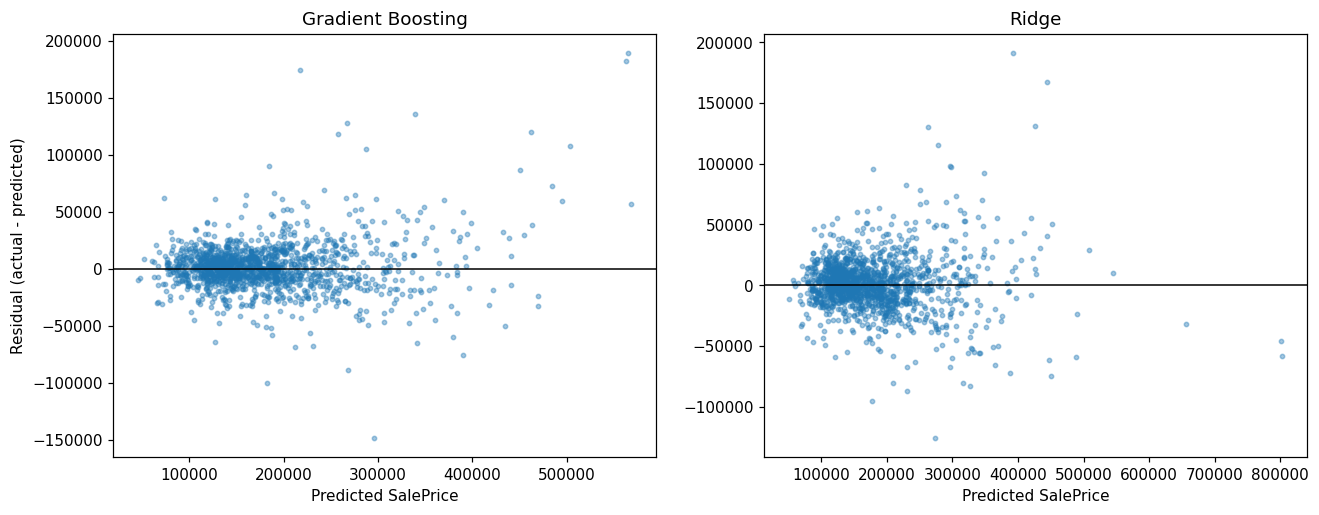

In [36]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)                      # left plot
plt.scatter(gb_pred, gb_resid, s=8, alpha=0.4)
plt.axhline(0, color='black', lw=1)
plt.title('Gradient Boosting')
plt.xlabel('Predicted SalePrice')
plt.ylabel('Residual (actual - predicted)')

plt.subplot(1, 2, 2)                      # right plot
plt.scatter(ridge_pred, ridge_resid, s=8, alpha=0.4)
plt.axhline(0, color='black', lw=1)
plt.title('Ridge')
plt.xlabel('Predicted SalePrice')

plt.show()

In [37]:
df.select_dtypes(include=['int64', 'float64'])

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
0,1,60,65.0,8450,7,5,2003,2003,196.0,706,...,0,61,0,0,0,0,0,2,2008,208500
1,2,20,80.0,9600,6,8,1976,1976,0.0,978,...,298,0,0,0,0,0,0,5,2007,181500
2,3,60,68.0,11250,7,5,2001,2002,162.0,486,...,0,42,0,0,0,0,0,9,2008,223500
3,4,70,60.0,9550,7,5,1915,1970,0.0,216,...,0,35,272,0,0,0,0,2,2006,140000
4,5,60,84.0,14260,8,5,2000,2000,350.0,655,...,192,84,0,0,0,0,0,12,2008,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1450,1456,60,62.0,7917,6,5,1999,2000,0.0,0,...,0,40,0,0,0,0,0,8,2007,175000
1451,1457,20,85.0,13175,6,6,1978,1988,119.0,790,...,349,0,0,0,0,0,0,2,2010,210000
1452,1458,70,66.0,9042,7,9,1941,2006,0.0,275,...,0,60,0,0,0,0,2500,5,2010,266500
1453,1459,20,68.0,9717,5,6,1950,1996,0.0,49,...,366,0,112,0,0,0,0,4,2010,142125


In [38]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
df.head(5)

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


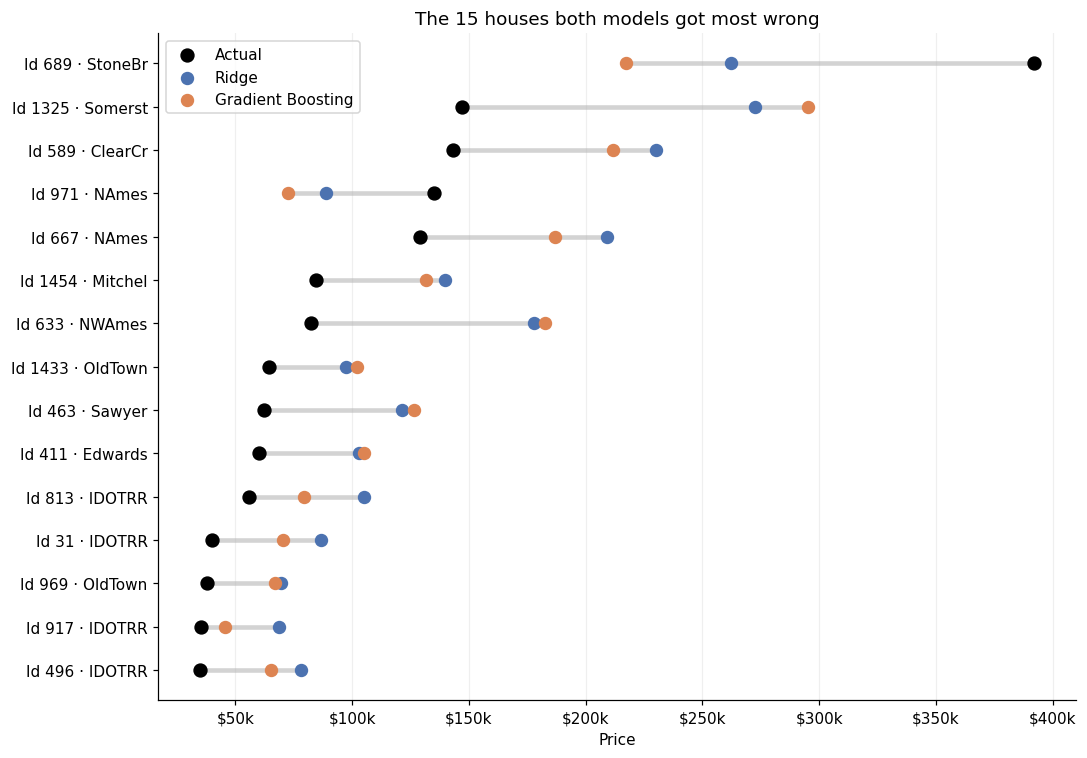

,Id,Neighborhood,SalePrice,ridge,gb,OverallQual,GrLivArea,TotalBsmtSF,GarageCars,GarageArea,1stFlrSF,FullBath,TotRmsAbvGrd,YearBuilt,YearRemodAdd,GarageYrBlt,MasVnrArea,Fireplaces,BsmtFinSF1,LotFrontage
14,689,StoneBr,392000,262179.0,217309.0,8,1419,1419,2,567,1419,2,7,2007,2007,2007.0,0.0,1,945,60.0
13,1325,Somerst,147000,272716.0,295446.0,8,1795,1795,3,895,1795,2,7,2006,2007,2007.0,428.0,1,0,75.0
12,589,ClearCr,143000,230206.0,211563.0,5,1473,1437,1,452,1473,1,5,1968,2003,1968.0,0.0,2,1324,65.0
11,971,NAmes,135000,88849.0,72607.0,4,1192,720,0,0,720,1,6,1949,1950,NaN,0.0,0,0,60.0
10,667,NAmes,129000,209356.0,187010.0,6,2380,1021,2,596,1465,2,7,1965,1979,1965.0,113.0,1,187,NaN
9,1454,Mitchel,84500,139743.0,131836.0,5,1140,1140,0,0,1140,1,6,2006,2006,NaN,0.0,0,0,90.0
8,633,NWAmes,82500,177698.0,182442.0,7,1411,1386,2,544,1411,2,6,1977,1977,1977.0,209.0,1,822,85.0
7,1433,OldTown,64500,97355.0,102123.0,4,968,656,1,216,968,2,5,1927,2007,1928.0,0.0,0,0,60.0
6,463,Sawyer,62383,121335.0,126599.0,5,864,864,1,360,864,1,5,1965,1965,1965.0,0.0,1,553,60.0
5,411,Edwards,60000,103128.0,105196.0,5,1276,1276,1,350,1276,1,5,1958,1958,1958.0,0.0,0,0,68.0


In [46]:
# top 15 numeric features most correlated with SalePrice (by absolute correlation)
top_feats = (df.select_dtypes('number').corr()['SalePrice']
               .drop(['SalePrice', 'Id'], errors='ignore')
               .abs().sort_values(ascending=False).head(15).index.tolist())

res = df[['Id', 'Neighborhood', 'SalePrice'] + top_feats].copy()
res['ridge'] = np.asarray(ridge_pred)
res['gb'] = np.asarray(gb_pred)

# how wrong each house is: average log gap of the two models (a percentage-style error)
log_gap = lambda p: (np.log1p(res[p]) - np.log1p(res['SalePrice'])).abs()
res['err'] = (log_gap('ridge') + log_gap('gb')) / 2

worst = res.nlargest(15, 'err').sort_values('SalePrice').reset_index(drop=True)

# plot
pos = np.arange(len(worst))
prices = worst[['SalePrice', 'ridge', 'gb']]

fig, ax = plt.subplots(figsize=(10, 7))
ax.hlines(pos, prices.min(axis=1), prices.max(axis=1), color='lightgray', lw=3, zorder=1)
ax.scatter(worst['SalePrice'], pos, color='black', s=70, label='Actual', zorder=3)
ax.scatter(worst['ridge'], pos, color='#4C72B0', s=60, label='Ridge', zorder=2)
ax.scatter(worst['gb'], pos, color='#DD8452', s=60, label='Gradient Boosting', zorder=2)

ax.set_yticks(pos)
ax.set_yticklabels([f"Id {i} · {n}" for i, n in zip(worst['Id'], worst['Neighborhood'])])
ax.xaxis.set_major_formatter(lambda v, _: f'${v/1000:.0f}k')
ax.set_xlabel('Price')
ax.legend()
ax.grid(axis='x', alpha=0.2)
for s in ('top', 'right'): ax.spines[s].set_visible(False)
ax.set_title('The 15 houses both models got most wrong')
plt.tight_layout()
plt.show()

pd.set_option('display.max_columns', None)
worst[['Id', 'Neighborhood', 'SalePrice', 'ridge', 'gb'] + top_feats].round(0).sort_values('SalePrice', ascending=False)


In [47]:
pd.reset_option('display.max_columns', None)
pd.reset_option('display.max_rows', None)